In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [37]:
df = pd.read_csv("../data/cleaned_data.csv", encoding="latin1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Month,Weekday
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday


In [38]:
df.shape

(392692, 11)

In [39]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'Month', 'Weekday'],
      dtype='str')

In [40]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
Month          0
Weekday        0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  int64  
 1   StockCode    392692 non-null  str    
 2   Description  392692 non-null  str    
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  str    
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  float64
 7   Country      392692 non-null  str    
 8   TotalPrice   392692 non-null  float64
 9   Month        392692 non-null  int64  
 10  Weekday      392692 non-null  str    
dtypes: float64(3), int64(3), str(5)
memory usage: 59.6 MB


In [43]:
df.describe()

,InvoiceNo,Quantity,UnitPrice,CustomerID,TotalPrice,Month
count,392692.000000,392692.000000,392692.000000,392692.000000,392692.000000,392692.000000
mean,560590.875047,13.119702,3.125914,15287.843865,22.631500,7.601871
std,13087.063759,180.492832,22.241836,1713.539549,311.099224,3.415015
min,536365.000000,1.000000,0.001000,12346.000000,0.001000,1.000000
25%,549234.000000,2.000000,1.250000,13955.000000,4.950000,5.000000
50%,561874.000000,6.000000,1.950000,15150.000000,12.450000,8.000000
75%,572061.000000,12.000000,3.750000,16791.000000,19.800000,11.000000
max,581587.000000,80995.000000,8142.750000,18287.000000,168469.600000,12.000000


**Checking for skewness**

In [44]:
# Skewness
numerical_columns = df.select_dtypes(include='number')
numerical_columns.skew()

InvoiceNo      -0.175439
Quantity      407.345663
UnitPrice     202.740861
CustomerID      0.030148
TotalPrice    448.521779
Month          -0.440356
dtype: float64

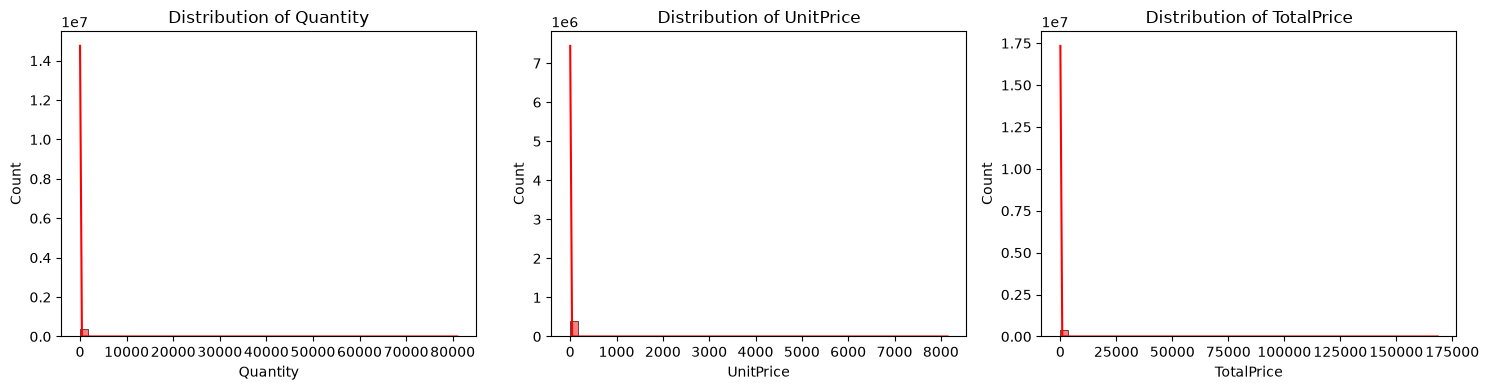

In [45]:
columns = ['Quantity', 'UnitPrice', 'TotalPrice']

fig, axes = plt.subplots(1,3, figsize=(15, 4))

for i, col in enumerate(columns):
    sns.histplot(df[col], bins=50, kde=True, color='red', ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.savefig('../images/12.skewed_distributions.png', bbox_inches='tight')
plt.show()

**Insight**
* Data is right skewed, i will later decide what better can be done

### Feature Engineering

In [46]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'Month', 'Weekday'],
      dtype='str')

1. **Recency:** How many days since the customer’s last purchase
- High recency: bad (inactive customer)
- Low recency: good (active customer)

2. **Frequency:** How many different orders the customer made
- High frequency: loyal customer (purchases often)
- Low frequency: one time buyer (purchases not so often)

3. **Monetary:** Total money spent by the customer
- High monetary: valuable customer
- Low monetary: low value customer

4. **CLV:** Total amount the customer spends during the 90-day period.

In [47]:
# Sets current date one day after latest invoice. (Adding one day helps ensure the latest purchase has a recency of at least 1 day)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
current_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
current_date

Timestamp('2011-12-10 12:50:00')

In [48]:
# RFM Calculation
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (current_date - x.max()).days, # current date - most recent purchase date
    'InvoiceNo': 'nunique', # number of unique invoices
    'TotalPrice': 'sum' # sum of money spent
})

In [49]:
# Renamed columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

In [50]:
# Create time split for last 90 days
split_date = df['InvoiceDate'].max() - pd.Timedelta(days=90)
split_date

Timestamp('2011-09-10 12:50:00')

In [51]:
# Create future dataframe for past 90 days to see what we know about the customer
train_df = df[df['InvoiceDate'] <= split_date]
train_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Month,Weekday
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday


In [52]:
# Create future dataframe for next 90 days to find what we want to predict
future_df = df[df['InvoiceDate'] > split_date]
future_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Month,Weekday
233840,566225,22384,LUNCH BAG PINK POLKADOT,6,2011-09-11 10:35:00,1.65,16899.0,United Kingdom,9.90,9,Sunday
233841,566225,20725,LUNCH BAG RED RETROSPOT,6,2011-09-11 10:35:00,1.65,16899.0,United Kingdom,9.90,9,Sunday
233842,566225,23169,CLASSIC GLASS COOKIE JAR,3,2011-09-11 10:35:00,4.15,16899.0,United Kingdom,12.45,9,Sunday
233843,566225,84029E,RED WOOLLY HOTTIE WHITE HEART.,3,2011-09-11 10:35:00,4.25,16899.0,United Kingdom,12.75,9,Sunday
233844,566225,21479,WHITE SKULL HOT WATER BOTTLE,3,2011-09-11 10:35:00,4.25,16899.0,United Kingdom,12.75,9,Sunday


In [53]:
# RFM calculation for training data
rfm_train = train_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (split_date - x.max()).days, # How many days before the split date was the customer’s last purchase?
    'InvoiceNo': 'nunique', # How many different orders the customer made before the split date.
    'TotalPrice': 'sum' # Total money spent before the split date.
})

rfm_train.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

In [54]:
# Calculates money spent by each customer during the next 90 days
clv = future_df.groupby('CustomerID')['TotalPrice'].sum()
clv = clv.reset_index()
clv.columns = ['CustomerID', 'CLV']
clv.head()

,CustomerID,CLV
0,12347.0,1519.14
1,12348.0,310.00
2,12349.0,1757.55
3,12352.0,944.23
4,12356.0,58.35


In [55]:
# Merge Features and Target
final_df = rfm_train.merge(clv, on='CustomerID', how='left')
# Fill customers with no future purchases
final_df['CLV'] = final_df['CLV'].fillna(0)

In [56]:
# Created some customer-level features from existing columns for the model
features = df.groupby('CustomerID').agg(
    TotalQuantity=('Quantity', 'sum'),
    UniqueProducts=('StockCode', 'nunique'),
    ActiveDays=('InvoiceDate', lambda x: x.dt.date.nunique()),
    CustomerTenureDays=('InvoiceDate', lambda x: (x.max() - x.min()).days),
    AverageUnitPrice=('UnitPrice', 'mean'),
    AverageQuantity=('Quantity', 'mean'),
    AverageTransactionValue=('TotalPrice', 'mean'),
    UniqueCountries=('Country', 'nunique')
).reset_index()

In [57]:
# Merge into your existing final_df
final_df = final_df.merge(features, on='CustomerID', how='left')

print(final_df.shape)
print(final_df.columns.tolist())

(3370, 13)
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'CLV', 'TotalQuantity', 'UniqueProducts', 'ActiveDays', 'CustomerTenureDays', 'AverageUnitPrice', 'AverageQuantity', 'AverageTransactionValue', 'UniqueCountries']


In [58]:
print(final_df.isnull().sum())
print("Duplicate customers:", final_df['CustomerID'].duplicated().sum())

CustomerID                 0
Recency                    0
Frequency                  0
Monetary                   0
CLV                        0
TotalQuantity              0
UniqueProducts             0
ActiveDays                 0
CustomerTenureDays         0
AverageUnitPrice           0
AverageQuantity            0
AverageTransactionValue    0
UniqueCountries            0
dtype: int64
Duplicate customers: 0


In [59]:
print("Dataset start:", df['InvoiceDate'].min())
print("Dataset end:", df['InvoiceDate'].max())

Dataset start: 2010-12-01 08:26:00
Dataset end: 2011-12-09 12:50:00


In [60]:
final_df.head()

,CustomerID,Recency,Frequency,Monetary,CLV,TotalQuantity,UniqueProducts,ActiveDays,CustomerTenureDays,AverageUnitPrice,AverageQuantity,AverageTransactionValue,UniqueCountries
0,12346.0,235,1,77183.60,0.00,74215,1,1,0,1.040000,74215.000000,77183.600000,1
1,12347.0,39,5,2790.86,1519.14,2458,103,7,365,2.644011,13.505495,23.681319,1
2,12348.0,158,3,1487.24,310.00,2341,22,4,282,5.764839,75.516129,57.975484,1
3,12350.0,219,1,334.40,0.00,197,17,1,0,3.841176,11.588235,19.670588,1
4,12352.0,171,5,1561.81,944.23,536,59,7,260,15.930706,6.305882,29.482824,1


**Explaination**
- Here, Above i used a time-based split where the last 90 days of transactions were treated as the future period. From all transactions before that period, I created RFM features for each customer. Then I calculated the customer’s actual spending during the next 90 days and used it as the CLV target. This allows the model to learn how past purchasing behavior relates to future customer value and also created some customer level features from the column.

In [61]:
# dropped CustomerID column because it is redundant now for model training
final_df.drop(columns=['CustomerID'], inplace=True)

In [62]:
final_df.head()

,Recency,Frequency,Monetary,CLV,TotalQuantity,UniqueProducts,ActiveDays,CustomerTenureDays,AverageUnitPrice,AverageQuantity,AverageTransactionValue,UniqueCountries
0,235,1,77183.60,0.00,74215,1,1,0,1.040000,74215.000000,77183.600000,1
1,39,5,2790.86,1519.14,2458,103,7,365,2.644011,13.505495,23.681319,1
2,158,3,1487.24,310.00,2341,22,4,282,5.764839,75.516129,57.975484,1
3,219,1,334.40,0.00,197,17,1,0,3.841176,11.588235,19.670588,1
4,171,5,1561.81,944.23,536,59,7,260,15.930706,6.305882,29.482824,1


In [63]:
final_df.describe()

,Recency,Frequency,Monetary,CLV,TotalQuantity,UniqueProducts,ActiveDays,CustomerTenureDays,AverageUnitPrice,AverageQuantity,AverageTransactionValue,UniqueCountries
count,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000
mean,94.485757,3.532938,1615.127193,843.869214,1419.099407,68.701484,4.536795,164.524332,4.065572,52.876287,78.319519,1.002374
std,79.982942,5.788414,6148.013905,5005.881501,5693.862293,93.099617,6.574593,130.785131,14.663906,1364.947518,1663.351829,0.048672
min,0.000000,1.000000,2.900000,0.000000,1.000000,1.000000,1.000000,0.000000,0.122500,1.000000,2.136970,1.000000
25%,25.000000,1.000000,264.640000,0.000000,185.000000,18.000000,1.000000,0.000000,2.289601,6.111111,12.847617,1.000000
50%,74.000000,2.000000,563.210000,173.480000,475.500000,41.000000,3.000000,172.000000,2.976875,10.000000,18.128344,1.000000
75%,151.000000,4.000000,1388.937500,687.547500,1196.750000,88.750000,5.000000,280.000000,3.894496,14.706553,25.530533,1.000000
max,283.000000,132.000000,178302.620000,168469.600000,196915.000000,1787.000000,132.000000,373.000000,451.420000,74215.000000,77183.600000,2.000000


In [64]:
final_df.dtypes

Recency                      int64
Frequency                    int64
Monetary                   float64
CLV                        float64
TotalQuantity                int64
UniqueProducts               int64
ActiveDays                   int64
CustomerTenureDays           int64
AverageUnitPrice           float64
AverageQuantity            float64
AverageTransactionValue    float64
UniqueCountries              int64
dtype: object

## Final Feature Visualization

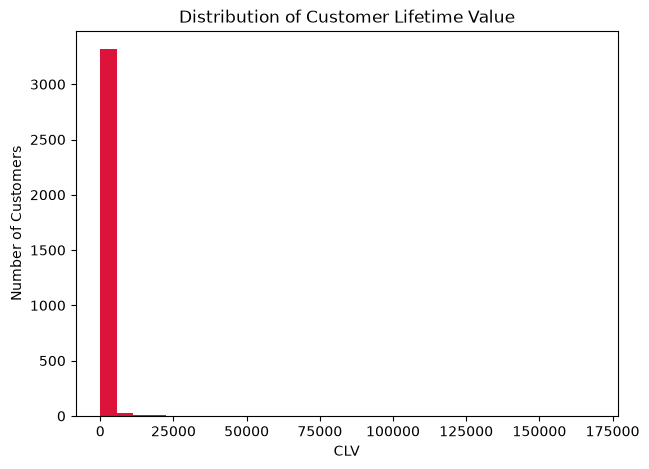

In [65]:
# Target distribution
plt.figure(figsize=(7,5)) 
plt.hist(final_df['CLV'], color='#DC143C', bins=30) 
plt.xlabel('CLV') 
plt.ylabel('Number of Customers') 
plt.title('Distribution of Customer Lifetime Value') 
plt.savefig('../images/13.clv_distribution.png', bbox_inches='tight')
plt.show()

**Insight**
- The customer lifetime value distribution is highly right-skewed, showing that the majority of customers generate low value, leaving few high value outliers.

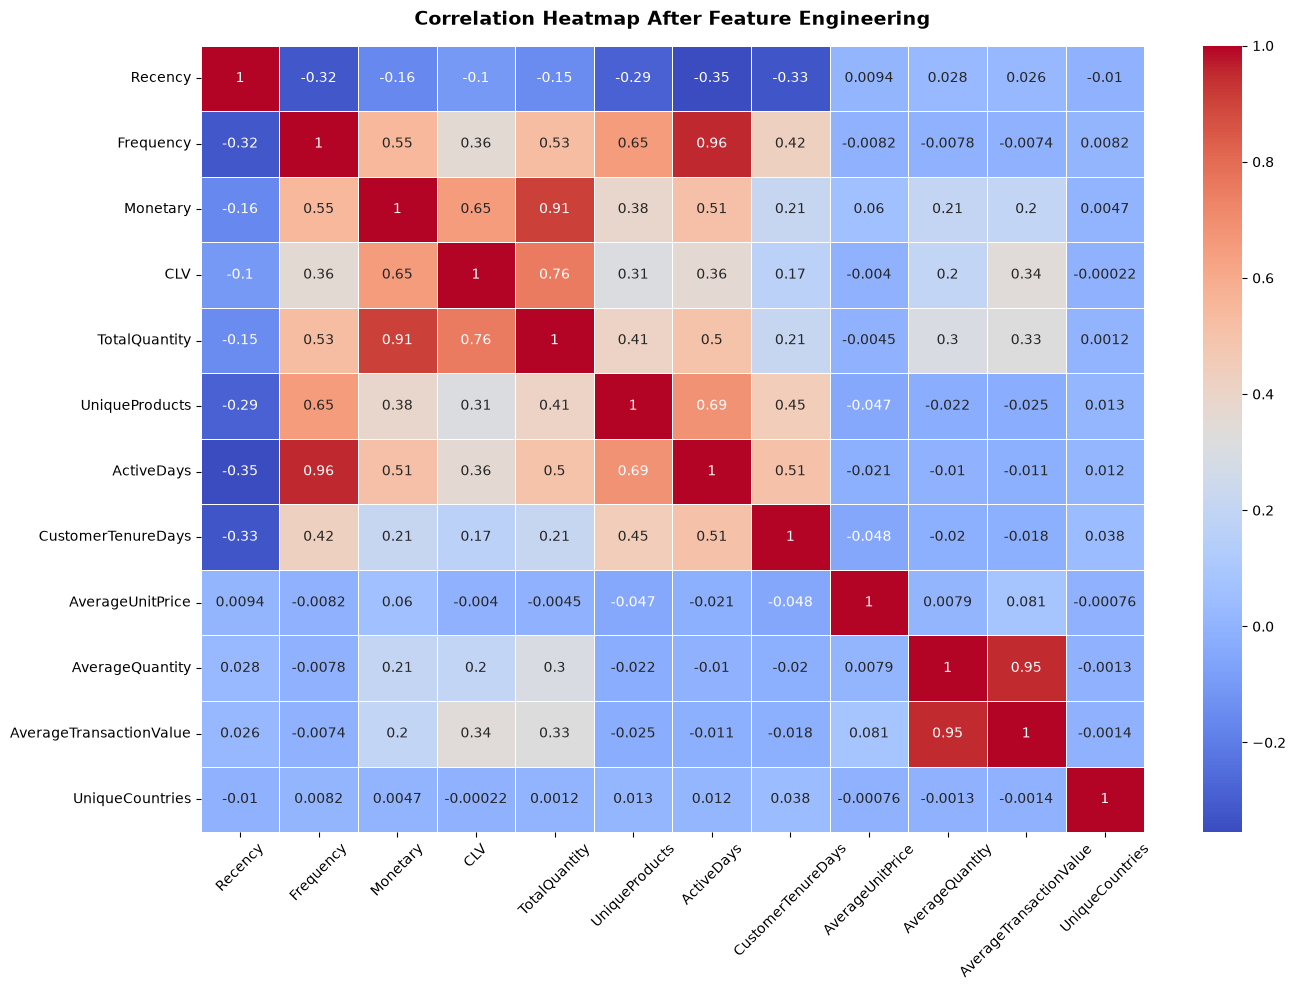

In [66]:
corr = final_df.corr() 
plt.figure(figsize=(14, 10)) 
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5, linecolor='white') 
plt.title('Correlation Heatmap After Feature Engineering', fontsize=14, fontweight='bold', pad=15) 
plt.xticks(rotation=45) 
plt.yticks(rotation=0) 
plt.tight_layout() 
plt.savefig('../images/14.correlation_heatmap_after_feature_engineering.png', bbox_inches='tight')
plt.show()

**Insight**
- TotalQuantity has the strongest positive correlation with CLV at 0.76 & Monetary value at 0.65, indicating that higher purchase volume and spending strongly predict customer lifetime value. Because many features showed limited correlation, new features and a target variable was engineered, and the dataset is now prepared for model training

In [67]:
final_df.skew()

Recency                     0.766241
Frequency                   9.256801
Monetary                   16.126953
CLV                        22.552758
TotalQuantity              18.119013
UniqueProducts              6.608784
ActiveDays                  8.127777
CustomerTenureDays          0.036238
AverageUnitPrice           25.908783
AverageQuantity            49.937026
AverageTransactionValue    41.123346
UniqueCountries            20.460328
dtype: float64

In [70]:
final_df.columns

Index(['Recency', 'Frequency', 'Monetary', 'CLV', 'TotalQuantity',
       'UniqueProducts', 'ActiveDays', 'CustomerTenureDays',
       'AverageUnitPrice', 'AverageQuantity', 'AverageTransactionValue',
       'UniqueCountries'],
      dtype='str')

In [71]:
print(f'The data has {final_df.shape[0]} rows and {final_df.shape[1]} columns')

The data has 3370 rows and 12 columns


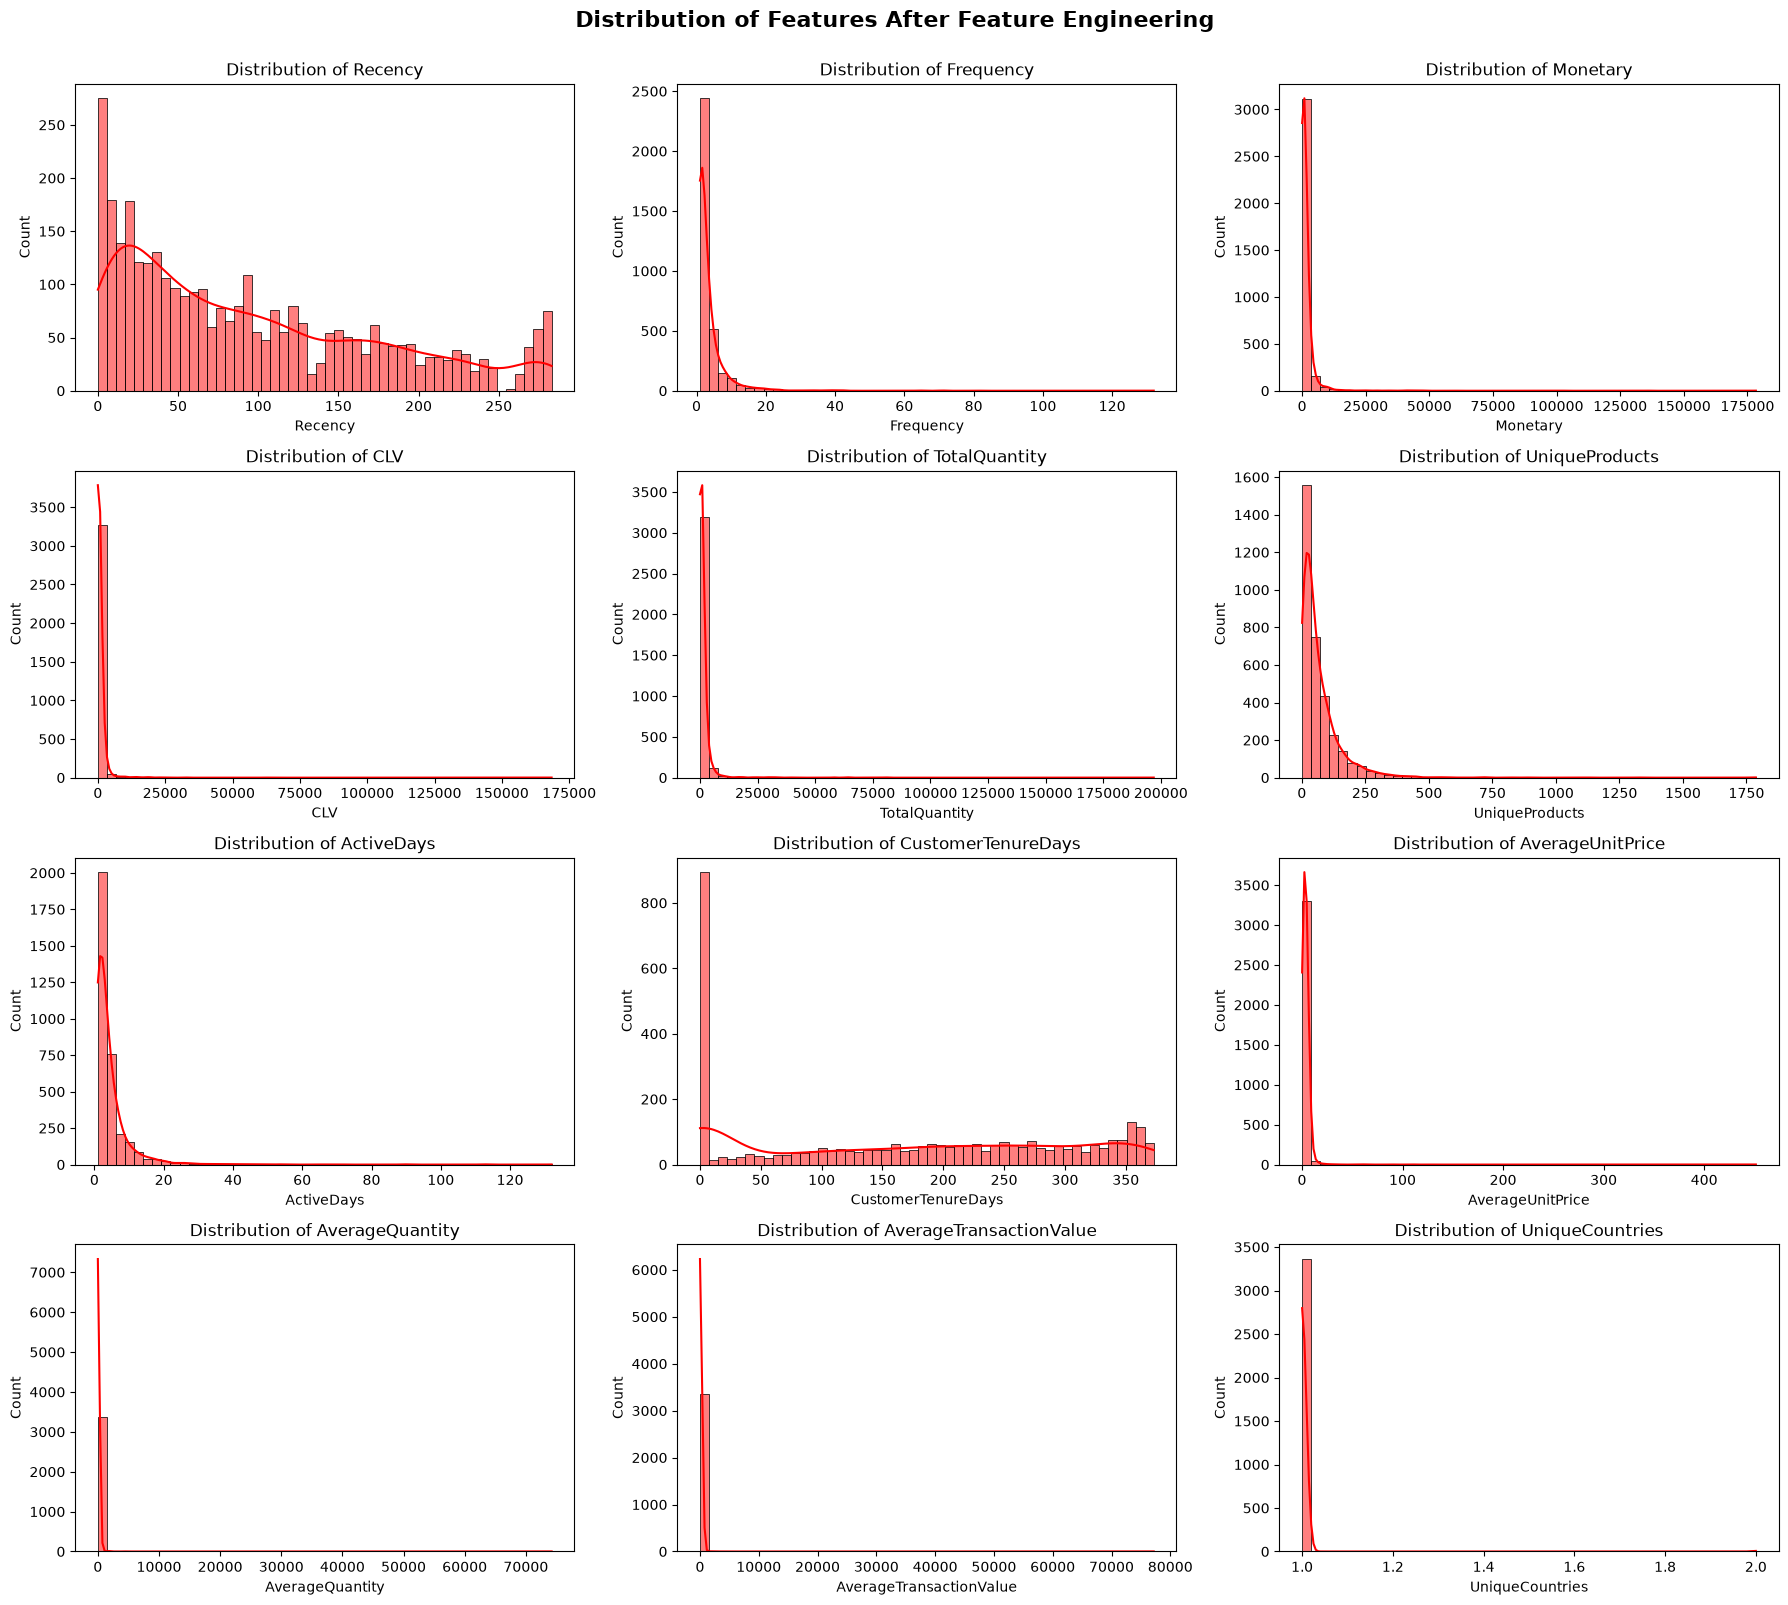

In [68]:
final_columns = final_df.columns

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, column in enumerate(final_columns):
    sns.histplot(final_df[column], bins=50, kde=True, color='red', ax=axes[i])
    axes[i].set_title(f'Distribution of {column}')

plt.suptitle('Distribution of Features After Feature Engineering', fontsize=16, fontweight='bold', y=1)
plt.tight_layout()
plt.savefig('../images/15.distribution_of_features_after_feature_engineering.png', bbox_inches='tight')
plt.show()

**Insight**
* Data is right skewed, so i will do log transformation after train test split

In [69]:
# saved the cleaned data to a new CSV file
final_df.to_csv('../data/final_data.csv', index=False)

**Now lets move to model training**